# MK Praktikum Unggulan Universitas Gunadarma
# Nama Mata Kuliah: Praktikum Robotika Cerdas (Tingkat 4)  

---
# Pertemuan VI

<div class="alert alert-warning">
<strong>MATERI INI WAJIB DIJALANKAN MENGGUNAKAN GPU.</strong>
    </div>

# Embedding dan Semantic Search

## Tujuan Praktikum

1. Memahami token embedding dan sentence embedding.
2. Menghitung similarity antar teks dengan cosine similarity.
3. Membuat semantic search sederhana dan mengevaluasinya dengan metric hit@k (Hit Rate at K).
4. Menganalisis waktu encode 1 juta kalimat dan keterbatasan embedding.

Model membaca angka, bukan kata.
Setiap kata atau kalimat diubah menjadi vektor, yaitu deretan angka, melalui proses embedding.
Vektor dari teks yang maknanya mirip cenderung berdekatan, sehingga kemiripan teks dapat dihitung.
Semantic search memanfaatkan hal ini untuk mencari dokumen berdasarkan makna.

## 0. Setup

Unggah `korpus_praktikum.jsonl` ke folder yang sama dengan notebook.
Model yang dipakai adalah `paraphrase-multilingual-MiniLM-L12-v2`, pretrained model yang mendukung lebih dari 50 bahasa termasuk Bahasa Indonesia.
Model ini menghasilkan vektor 384 dimensi dan diunduh otomatis saat cell pertama dijalankan (sekitar 470 MB).

In [ ]:
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import display
from transformers import AutoModel, AutoTokenizer

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
MODEL_NAME = 'sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2'
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
model = AutoModel.from_pretrained(MODEL_NAME).to(DEVICE).eval()

print('Device           :', torch.cuda.get_device_name(0) if DEVICE == 'cuda' else 'CPU')
print('Dimensi embedding:', model.config.hidden_size)

Jika device tertulis `CPU`, ganti runtime ke GPU lalu jalankan ulang. Bagian 5 hanya bisa dijalankan di GPU.

### Corpus

Setiap dokumen memiliki kolom `id`, `judul`, dan `teks`.
Prefix `id` menunjukkan topik: `gan` (GAN), `nlp` (text processing dan LSTM), `hpc` (komputasi CPU dan GPU), dan `emb` (embedding).
Dokumen dengan prefix `lain-` tidak relevan dengan topik praktikum, sehingga tidak dipakai di sini.

In [2]:
CORPUS_PATH = Path('korpus_praktikum.jsonl')
if not CORPUS_PATH.exists():
    raise FileNotFoundError('Upload korpus_praktikum.jsonl ke folder notebook, lalu jalankan ulang cell ini.')

corpus = pd.read_json(CORPUS_PATH, lines=True)
corpus = corpus[~corpus['id'].str.startswith('lain-')].reset_index(drop=True)
corpus['group'] = corpus['id'].str.split('-').str[0]

print('Jumlah dokumen:', len(corpus))
display(corpus[['id', 'group', 'judul']].head())
print('Contoh teks:', corpus.loc[0, 'teks'])

Jumlah dokumen: 30


,id,group,judul
0,gan-01,gan,Pengertian GAN
1,gan-02,gan,Peran generator
2,gan-03,gan,Peran discriminator
3,gan-04,gan,Vektor laten dan latent_dim
4,gan-05,gan,Training GAN secara bergantian


Contoh teks: Generative Adversarial Network atau GAN adalah model generatif yang terdiri atas dua jaringan saraf, yaitu generator dan discriminator. Kedua jaringan dilatih bersama dengan tujuan yang saling berlawanan. Generator berusaha membuat data buatan yang menyerupai data asli, sedangkan discriminator berusaha membedakan data asli dari data buatan. Setelah training, generator dapat dipakai untuk membuat contoh data baru, misalnya gambar.


## 1. Token Menjadi Vektor

Model memecah teks menjadi token, yaitu potongan kata atau subkata.
Setiap token memiliki nomor unik yang disebut *token ID*.
Token ID digunakan untuk mengambil baris pada *embedding table*, yaitu tabel yang setiap barisnya berisi vektor untuk satu token.

In [3]:
torch.manual_seed(42)
embedding_table = torch.nn.Embedding(num_embeddings=1000, embedding_dim=8)
token_ids = torch.tensor([[5, 27, 3, 0],
                          [12, 5, 0, 0]])  # 0 adalah padding agar panjang kedua kalimat sama
token_vectors = embedding_table(token_ids)

print('Shape input :', tuple(token_ids.shape))
print('Shape output:', tuple(token_vectors.shape))
print('Vector ID 5 = baris ke-5 table?', torch.allclose(embedding_table.weight[5], token_vectors[0, 0]))

Shape input : (2, 4)
Shape output: (2, 4, 8)
Vector ID 5 = baris ke-5 table? True


Input `(2, 4)` berarti 2 kalimat dengan 4 token masing-masing.
Output `(2, 4, 8)` berarti setiap token sekarang berupa vektor 8 angka.

Angka di embedding table awal masih acak.
Selama training, angka tersebut disesuaikan, sehingga token dengan pemakaian serupa mendapat vektor yang berdekatan.

Metode lama, *one-hot encoding*, membuat satu dimensi untuk setiap token.
Untuk vocabulary 10.000 token, dibutuhkan 10.000 dimensi. Embedding cukup memakai ratusan dimensi.

## 2. Kalimat Menjadi Satu Vektor

Untuk membandingkan kalimat, setiap kalimat membutuhkan satu vektor. Pretrained model membuatnya dalam tiga tahap:

1. *Tokenization*: kalimat dipecah menjadi token.
2. 12 layer Transformer menghasilkan satu vektor 384 angka untuk setiap token. Vektor ini sudah memperhitungkan konteks kalimat.
3. *Mean pooling*: vektor semua token dirata-ratakan menjadi satu sentence vektor.

Mean pooling diperlukan karena jumlah token setiap kalimat berbeda, sedangkan hasil akhirnya harus berukuran sama.

In [4]:
sentence = 'Mahasiswa menjalankan notebook di server GPU.'
batch = tokenizer(sentence, return_tensors='pt').to(DEVICE)
print('Token:', tokenizer.convert_ids_to_tokens(batch['input_ids'][0]))

with torch.inference_mode():
    token_vectors = model(**batch).last_hidden_state
print('Token vectors  :', tuple(token_vectors.shape))
print('Sentence vector:', tuple(token_vectors.mean(dim=1).shape))

Token: ['<s>', '▁Mahasiswa', '▁menjalankan', '▁notebook', '▁di', '▁server', '▁GPU', '.', '</s>']
Token vectors  : (1, 9, 384)
Sentence vector: (1, 384)


`<s>` dan `</s>` menandai awal dan akhir kalimat. `▁` menandai awal sebuah kata.
Jumlah token tidak selalu sama dengan jumlah kata, karena kata yang jarang muncul bisa dipecah menjadi beberapa token.

Fungsi `encode` menjalankan ketiga tahap tersebut untuk banyak teks sekaligus, per *batch*, agar penggunaan memory tidak terlalu besar.

In [5]:
def encode(texts, batch_size=64):
    """Ubah list teks menjadi array embedding berbentuk (jumlah teks, 384)."""
    outputs = []
    for start in range(0, len(texts), batch_size):
        batch = tokenizer(texts[start:start + batch_size], padding=True, truncation=True,
                          max_length=256, return_tensors='pt').to(model.device)
        with torch.inference_mode():
            token_vectors = model(**batch).last_hidden_state

        # Mean pooling: token padding tidak ikut dirata-ratakan.
        mask = batch['attention_mask'].unsqueeze(-1).float()
        outputs.append(((token_vectors * mask).sum(dim=1) / mask.sum(dim=1)).cpu())
    return torch.cat(outputs).numpy()

doc_embeddings = encode(corpus['teks'].tolist())
print('Shape embedding corpus:', doc_embeddings.shape)

Shape embedding corpus: (30, 384)


Bentuk `(30, 384)` berarti ada 30 dokumen, dan setiap dokumen diwakili 384 angka.
Satu angka tidak punya arti sendiri, karena makna dokumen tersebar di seluruh dimensi. Perbandingan karena itu dilakukan pada vector secara utuh.

## 3. Cosine Similarity

Cosine similarity mengukur seberapa mirip dua vektor dengan melihat arahnya. Panjang vektor tidak ikut dihitung.

Nilainya berada di antara -1 dan 1:

- Mendekati 1: arah kedua vektor hampir sama, sehingga maknanya mirip.
- Mendekati 0: kedua vektor tidak berhubungan.
- Mendekati -1: arah kedua vektor berlawanan.

$$\cos(a, b) = \frac{a \cdot b}{\|a\| \, \|b\|}$$

Semantic search memakai nilai ini untuk mengurutkan dokumen dari yang paling relevan.
Setelah setiap vektor di-normalize (panjangnya dibuat 1), rumus di atas menjadi dot product.
Dengan begitu, similarity seluruh pasangan dokumen dapat dihitung sekaligus dengan satu matrix multiplication.

In [6]:
def normalize(x):
    return x / np.linalg.norm(x, axis=1, keepdims=True)

doc_normalized = normalize(doc_embeddings)
similarity = doc_normalized @ doc_normalized.T
print('Shape similarity matrix:', similarity.shape)

# Rata-rata score antar group, tanpa membandingkan dokumen dengan dirinya sendiri.
groups = corpus['group'].values
group_order = corpus['group'].unique()
off_diagonal = similarity.copy()
np.fill_diagonal(off_diagonal, np.nan)
group_mean = pd.DataFrame(
    [[np.nanmean(off_diagonal[np.ix_(groups == a, groups == b)]) for b in group_order] for a in group_order],
    index=group_order, columns=group_order)
display(group_mean.round(3))

Shape similarity matrix: (30, 30)


,gan,nlp,hpc,emb
gan,0.511,0.338,0.304,0.304
nlp,0.338,0.417,0.281,0.331
hpc,0.304,0.281,0.458,0.232
emb,0.304,0.331,0.232,0.379


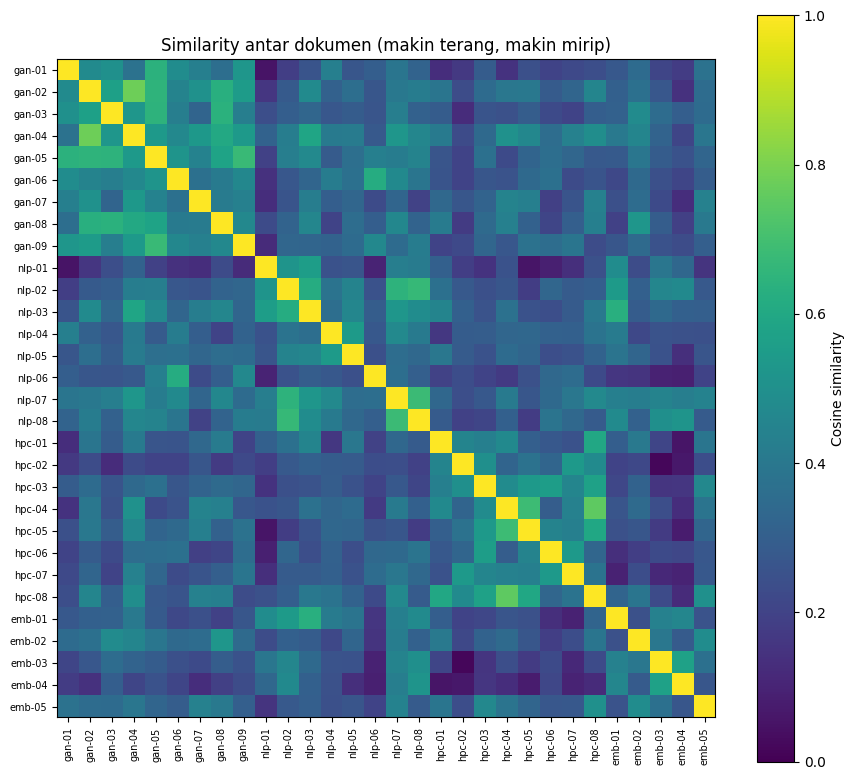

In [7]:
fig, ax = plt.subplots(figsize=(9, 8))
image = ax.imshow(similarity, cmap='viridis', vmin=0, vmax=1)
ax.set_xticks(range(len(corpus)), corpus['id'], rotation=90, fontsize=7)
ax.set_yticks(range(len(corpus)), corpus['id'], fontsize=7)
fig.colorbar(image, label='Cosine similarity')
ax.set_title('Similarity antar dokumen (makin terang, makin mirip)')
fig.tight_layout()
plt.show()

Pada tabel rata-rata, nilai diagonal (pasangan dalam group yang sama) seharusnya lebih tinggi daripada nilai di luar diagonal.
Pada heatmap, diagonal selalu terang karena setiap dokumen dibandingkan dengan dirinya sendiri.
Area terang di luar diagonal menunjukkan group yang topiknya berdekatan, misalnya `emb` dan `nlp`.

PCA bisa menggambar vektor 384 dimensi dalam 2D, tetapi sebagian informasi ikut hilang.
Untuk angka yang akurat, gunakan similarity matrix.

## 4. Search Engine Sederhana

Keyword search hanya menemukan dokumen yang memuat kata yang sama persis dengan query.
Semantic search bekerja dalam tiga langkah:

1. Query di-encode menjadi vektor, lalu di-normalize.
2. `torch.matmul` menghitung score query terhadap semua dokumen.
3. `torch.topk` mengambil `k` dokumen dengan score tertinggi.

In [8]:
doc_tensor = torch.from_numpy(doc_normalized).to(DEVICE)

def search(query, k=3):
    """Kembalikan k dokumen dengan score tertinggi untuk query."""
    query_vector = torch.from_numpy(normalize(encode([query]))).to(DEVICE)
    scores = torch.matmul(query_vector, doc_tensor.T)[0]
    top = torch.topk(scores, k)
    indices = top.indices.cpu().numpy()
    return pd.DataFrame({
        'rank': range(1, k + 1),
        'score': top.values.cpu().numpy().round(3),
        'id': corpus['id'].values[indices],
        'judul': corpus['judul'].values[indices],
    })

# Query dengan kata dari judul vs query dengan kata lain, targetnya dokumen yang sama.
for query in ['Keterbatasan embedding', 'Skor kemiripan tinggi belum tentu maknanya sama']:
    print('Query:', query)
    display(search(query))

Query: Keterbatasan embedding


,rank,score,id,judul
0,1,0.288,emb-01,Sentence embedding
1,2,0.261,emb-04,Keterbatasan embedding
2,3,0.258,gan-09,Mode collapse


Query: Skor kemiripan tinggi belum tentu maknanya sama


,rank,score,id,judul
0,1,0.463,emb-04,Keterbatasan embedding
1,2,0.348,emb-03,Pencarian semantik
2,3,0.286,emb-02,Cosine similarity


Kedua query memiliki dokumen target yang sama, yaitu `emb-04`.
Query pertama memakai kata dari judul dokumen, sedangkan query kedua tidak.
Jika `emb-04` tetap berada di peringkat teratas untuk query kedua, model mengenali makna query, tidak hanya kata yang sama.

### Evaluasi Search Engine

Evaluasi memakai 8 test query dengan dokumen target yang sudah diketahui.
Query ditulis dengan kata yang berbeda dari dokumen target, sehingga pengujian tidak hanya mengukur kecocokan kata.

Metric yang dipakai adalah hit@k, yaitu proporsi query yang dokumen targetnya masuk ke `k` hasil teratas.
Contohnya, hit@3 = 0,75 berarti 6 dari 8 query menemukan dokumen target di top-3.

In [9]:
TEST_QUERIES = [
    ('Kenapa generator cuma menghasilkan gambar yang mirip-mirip?', 'gan-09'),
    ('Bagian GAN yang menilai gambar asli atau palsu', 'gan-03'),
    ('Memecah kalimat menjadi potongan kata', 'nlp-01'),
    ('Mematikan sebagian neuron secara acak saat training', 'nlp-06'),
    ('Format angka yang memorinya setengah dari 32 bit', 'hpc-04'),
    ('Berapa kali lebih cepat GPU dibanding CPU?', 'hpc-07'),
    ('Mengukur seberapa searah dua vektor', 'emb-02'),
    ('Menggambar data berdimensi tinggi di bidang dua dimensi', 'emb-05'),
]

def evaluate_queries(query_pairs):
    """Untuk setiap (query, id target), cari rank dokumen target di antara semua dokumen."""
    rows = []
    for query, target in query_pairs:
        results = search(query, k=len(corpus))
        target_rank = int(results.loc[results['id'] == target, 'rank'].iloc[0])
        rows.append({'query': query, 'target': target, 'target_rank': target_rank,
                     'top_result': results.loc[0, 'id']})
    return pd.DataFrame(rows)

def show_hit_rate(evaluation):
    for k in [1, 3, 5]:
        print(f'hit@{k}: {(evaluation["target_rank"] <= k).mean():.2f}')

evaluation = evaluate_queries(TEST_QUERIES)
display(evaluation)
show_hit_rate(evaluation)

,query,target,target_rank,top_result
0,Kenapa generator cuma menghasilkan gambar yang...,gan-09,5,gan-02
1,Bagian GAN yang menilai gambar asli atau palsu,gan-03,2,gan-05
2,Memecah kalimat menjadi potongan kata,nlp-01,5,nlp-02
3,Mematikan sebagian neuron secara acak saat tra...,nlp-06,3,gan-06
4,Format angka yang memorinya setengah dari 32 bit,hpc-04,1,hpc-04
5,Berapa kali lebih cepat GPU dibanding CPU?,hpc-07,1,hpc-07
6,Mengukur seberapa searah dua vektor,emb-02,1,emb-02
7,Menggambar data berdimensi tinggi di bidang du...,emb-05,1,emb-05


hit@1: 0.50
hit@3: 0.75
hit@5: 1.00


`target_rank = 1` berarti dokumen target ada di peringkat teratas.
Jika `top_result` berbeda dari `target`, buka dokumen tersebut dan cek apakah topiknya dekat, atau hanya kata-katanya yang mirip.

hit@5 tidak pernah lebih kecil dari hit@1.
Namun, makin besar `k`, makin banyak dokumen tidak relevan yang ikut masuk.

## 5. Skala Besar: 1 Juta Kalimat

Corpus hanya berisi 30 dokumen, sedangkan sistem nyata bisa memuat jutaan teks.
Bagian ini membuat dummy dataset untuk mengukur waktu dan memory.

Kalimat dummy disusun dari template: subjek, kegiatan, objek, tempat, dan waktu.
Ada 96.000 kombinasi, sehingga setiap kalimat rata-rata muncul sekitar 10 kali.

In [10]:
rng = np.random.default_rng(42)
SUBJECTS = ['Mahasiswa', 'Dosen', 'Peneliti', 'Asisten lab', 'Tim kami', 'Programmer', 'Siswa', 'Teknisi',
            'Analis data', 'Pengajar']
ACTIVITIES = ['melatih', 'menguji', 'membandingkan', 'menjalankan', 'memperbaiki', 'mempelajari',
              'mengamati', 'menyiapkan', 'membahas', 'merancang']
OBJECTS = ['model GAN', 'jaringan LSTM', 'program GPU', 'kode Python', 'dataset gambar', 'model embedding',
           'laporan praktikum', 'server komputasi', 'resep masakan', 'jadwal pertandingan', 'peta kota',
           'data cuaca']
PLACES = ['di laboratorium', 'di kelas', 'di rumah', 'di perpustakaan', 'di kantor', 'secara daring',
          'di kampus', 'di ruang rapat', 'di kafe', 'di asrama']
TIMES = ['pagi ini', 'kemarin sore', 'setiap minggu', 'sebelum ujian', 'tadi malam', 'besok siang',
         'akhir pekan ini', 'bulan lalu']

def make_sentences(n):
    """Buat n kalimat dummy dari template secara random."""
    parts = [rng.choice(words, size=n) for words in (SUBJECTS, ACTIVITIES, OBJECTS, PLACES, TIMES)]
    return [' '.join(words) + '.' for words in zip(*parts)]

dummy_sentences = make_sentences(100_000)
print('Contoh:', dummy_sentences[:3])

Contoh: ['Mahasiswa menyiapkan data cuaca di perpustakaan akhir pekan ini.', 'Teknisi membahas data cuaca di kafe sebelum ujian.', 'Siswa mempelajari data cuaca di kafe bulan lalu.']


### Waktu Encode

Waktu encode diukur untuk beberapa ukuran data. CPU hanya diukur pada 1.000 kalimat karena prosesnya lambat.
Satu putaran *warmup* dijalankan dulu dan tidak dihitung, karena putaran pertama biasanya lebih lambat akibat inisialisasi.

In [11]:
def time_encode(sentences, device, batch_size=256):
    """Kembalikan waktu encode dalam detik pada device tertentu."""
    model.to(device)
    encode(sentences[:batch_size], batch_size=batch_size)  # warmup
    start = time.perf_counter()
    encode(sentences, batch_size=batch_size)
    return time.perf_counter() - start

plan = [('cpu', 1_000)]
if DEVICE == 'cuda':
    plan += [('cuda', 1_000), ('cuda', 10_000), ('cuda', 100_000)]

rows = []
for device, n in plan:
    seconds = time_encode(dummy_sentences[:n], device)
    rows.append({'device': device, 'n_sentences': n, 'seconds': round(seconds, 2),
                 'sentences_per_second': round(n / seconds)})
    print(f'{device:4s} | {n:7,d} kalimat | {seconds:.2f} detik', flush=True)
model.to(DEVICE)

benchmark = pd.DataFrame(rows)
display(benchmark)

cpu_speed = benchmark.loc[benchmark['device'] == 'cpu', 'sentences_per_second'].iloc[0]
print(f'Estimasi 1 juta kalimat di CPU: {1_000_000 / cpu_speed / 60:.1f} menit')

cpu  |   1,000 kalimat | 8.73 detik
cuda |   1,000 kalimat | 0.33 detik
cuda |  10,000 kalimat | 3.02 detik
cuda | 100,000 kalimat | 33.26 detik


,device,n_sentences,seconds,sentences_per_second
0,cpu,1000,8.73,115
1,cuda,1000,0.33,3051
2,cuda,10000,3.02,3312
3,cuda,100000,33.26,3007


Estimasi 1 juta kalimat di CPU: 144.9 menit


`sentences_per_second` adalah throughput, yaitu jumlah kalimat yang diproses per detik. Makin besar nilainya, makin cepat prosesnya.

Estimasi CPU untuk 1 juta kalimat dihitung dari 1.000.000 dibagi throughput CPU pada 1.000 kalimat.
Hasilnya hanya perkiraan kasar, karena throughput bisa turun pada data yang lebih besar.

### Encode 1 Juta Kalimat di GPU

Cell ini bisa memakan beberapa menit.
Hasilnya disimpan ke `embedding_1m.npy`, sehingga tidak perlu diulang selama file itu ada.

In [12]:
EMBEDDING_FILE = Path('embedding_1m.npy')
sentences_1m = make_sentences(1_000_000)

if DEVICE != 'cuda':
    print('Di-skip: bagian ini membutuhkan GPU.')
else:
    if EMBEDDING_FILE.exists():
        embeddings_1m = np.load(EMBEDDING_FILE)
        print('Embedding dimuat dari file.')
    else:
        start = time.perf_counter()
        embeddings_1m = encode(sentences_1m, batch_size=512)
        print(f'Waktu encode 1 juta kalimat di GPU: {(time.perf_counter() - start) / 60:.1f} menit')
        np.save(EMBEDDING_FILE, embeddings_1m)

    print('Shape:', embeddings_1m.shape)
    print(f'Memory FP32: {embeddings_1m.nbytes / 2**20:,.0f} MiB')
    print(f'Memory BF16: {embeddings_1m.nbytes / 2 / 2**20:,.0f} MiB (setengah dari FP32)')

Waktu encode 1 juta kalimat di GPU: 6.1 menit
Shape: (1000000, 384)
Memory FP32: 1,465 MiB
Memory BF16: 732 MiB (setengah dari FP32)


Memory dihitung dengan rumus: jumlah teks × dimensi × byte per angka.
FP32 memakai 4 byte per angka, jadi 1.000.000 × 384 × 4 byte ≈ 1.465 MiB.
BF16 memakai 2 byte per angka, sehingga memory-nya setengah dengan presisi yang lebih rendah.

### Top-10 Retrieval dari 1 Juta Kalimat

Search tetap berupa satu matrix multiplication, sama seperti pada 30 dokumen.
Waktu encode query dan waktu search diukur terpisah.

In [13]:
if DEVICE == 'cuda':
    embeddings_1m_gpu = torch.nn.functional.normalize(torch.from_numpy(embeddings_1m).to(DEVICE), dim=1)

    def search_1m(query, k=10):
        start = time.perf_counter()
        query_vector = torch.nn.functional.normalize(torch.from_numpy(encode([query])).to(DEVICE), dim=1)
        torch.cuda.synchronize()
        encode_time = time.perf_counter() - start

        start = time.perf_counter()
        # Kalimat dummy banyak yang kembar, jadi ambil kandidat lebih banyak lalu sisakan k kalimat unik.
        top = torch.topk(torch.matmul(query_vector, embeddings_1m_gpu.T)[0], k * 50)
        indices = top.indices.cpu().numpy()  # .cpu() menunggu GPU selesai
        search_time = time.perf_counter() - start

        print(f'Query: {query}')
        print(f'Encode query: {encode_time * 1000:.1f} ms | search 1 juta vector: {search_time * 1000:.1f} ms')
        result = pd.DataFrame({'score': top.values.cpu().numpy().round(3),
                               'kalimat': [sentences_1m[i] for i in indices]}).drop_duplicates('kalimat').head(k)
        result.insert(0, 'rank', range(1, len(result) + 1))
        display(result.reset_index(drop=True))

    search_1m('Dosen sedang mengoreksi tugas mahasiswa di kampus')  # warmup
    search_1m('Orang yang memasak makanan di rumah pada malam hari')

Query: Dosen sedang mengoreksi tugas mahasiswa di kampus
Encode query: 25.1 ms | search 1 juta vector: 8.9 ms


,rank,score,kalimat
0,1,0.8,Dosen memperbaiki model embedding di kampus se...
1,2,0.8,Dosen memperbaiki model embedding di kampus se...
2,3,0.8,Dosen memperbaiki model embedding di kampus se...
3,4,0.8,Dosen memperbaiki model embedding di kampus se...
4,5,0.8,Dosen memperbaiki model embedding di kampus se...
5,6,0.8,Dosen memperbaiki model embedding di kampus se...
6,7,0.8,Dosen memperbaiki model embedding di kampus se...
7,8,0.8,Dosen memperbaiki model embedding di kampus se...
8,9,0.8,Dosen memperbaiki model embedding di kampus se...
9,10,0.8,Dosen memperbaiki model embedding di kampus se...


Query: Orang yang memasak makanan di rumah pada malam hari
Encode query: 10.9 ms | search 1 juta vector: 6.5 ms


,rank,score,kalimat
0,1,0.826,Teknisi menyiapkan resep masakan di rumah tadi...
1,2,0.826,Teknisi menyiapkan resep masakan di rumah tadi...
2,3,0.826,Teknisi menyiapkan resep masakan di rumah tadi...
3,4,0.826,Teknisi menyiapkan resep masakan di rumah tadi...
4,5,0.826,Teknisi menyiapkan resep masakan di rumah tadi...
5,6,0.826,Teknisi menyiapkan resep masakan di rumah tadi...
6,7,0.826,Teknisi menyiapkan resep masakan di rumah tadi...
7,8,0.826,Teknisi menyiapkan resep masakan di rumah tadi...
8,9,0.826,Teknisi menyiapkan resep masakan di rumah tadi...
9,10,0.826,Teknisi menyiapkan resep masakan di rumah tadi...


Search pada 1 juta vektor biasanya hanya beberapa milidetik.
Yang mahal adalah encode seluruh teks, dan itu cukup dilakukan sekali.

Karena kalimat dummy berulang, top-10 mentah bisa memuat kalimat yang sama beberapa kali.
Sistem karena itu mengambil 500 kandidat, lalu membuang duplikat sampai tersisa 10 kalimat unik. Cara ini disebut deduplication.

Periksa juga apakah kalimat teratas sesuai dengan maksud query.

## 6. Limitation Embedding

Embedding dipelajari dari pola pada data training.
Perbedaan makna yang halus, misalnya negasi, sering tidak tertangkap.

In [14]:
def pair_score(a, b):
    vectors = normalize(encode([a, b]))
    return round(float(vectors[0] @ vectors[1]), 3)

PAIRS = [
    ('Sinonim', 'Saya suka kopi.', 'Saya gemar minum kopi.'),
    ('Negasi', 'Saya suka kopi.', 'Saya tidak suka kopi.'),
    ('Tidak berkaitan', 'Saya suka kopi.', 'Kucing itu tidur di sofa.'),
    ('Kata sama, arti beda', 'Generator listrik di gedung mati.', 'Generator pada GAN membuat gambar.'),
]
display(pd.DataFrame([(category, a, b, pair_score(a, b)) for category, a, b in PAIRS],
                     columns=['category', 'sentence_a', 'sentence_b', 'score']))

,category,sentence_a,sentence_b,score
0,Sinonim,Saya suka kopi.,Saya gemar minum kopi.,0.914
1,Negasi,Saya suka kopi.,Saya tidak suka kopi.,0.553
2,Tidak berkaitan,Saya suka kopi.,Kucing itu tidur di sofa.,0.060
3,"Kata sama, arti beda",Generator listrik di gedung mati.,Generator pada GAN membuat gambar.,0.417


Kalimat "suka" dan "tidak suka" berlawanan maknanya, tetapi score-nya tetap tinggi.
Kedua kalimat punya kata yang hampir sama, dan "tidak" hanya satu dari banyak token yang dirata-ratakan pada mean pooling.
Kata "generator" juga bisa menaikkan score, walaupun topiknya berbeda.

Akibatnya, hasil search bisa berisi topik yang benar tetapi isi yang bertentangan.
Untuk keperluan yang penting, hasilnya tetap perlu dicek manusia.

## Ringkasan

- Token diubah menjadi vektor melalui embedding table.
- Kalimat diubah menjadi satu vektor 384 angka dengan pretrained model dan mean pooling.
- Cosine similarity mengukur kemiripan arah dua vektor.
- Kualitas semantic search diukur dengan hit@k.
- Score tinggi tidak selalu berarti makna sama.

# Instruksi Tugas Praktikum Prodi di FTI dan FIKTI

<div class="alert alert-info">
    <strong>Daftar Program Studi:</strong><br>
    <hr>
    <strong> Fakultas Ilmu Komputer dan Teknologi Informasi</strong><br>
    - Sistem Informasi (S1 - SI)<br>
    - Sistem Komputer (S1 - SK)<br>
    - Manajemen Informatika (D3 - MI)<br>
    - Teknik Komputer (D3 - TK)<br><br>
    <strong> Fakultas Teknologi Industri</strong><br>
    - Informatika (S1)<br>
    - Teknik Elektro (S1)<br>
    - Teknik Mesin (S1)<br>
    - Teknik Industri (S1)<br>
    - Agroteknologi (S1)<br>
</div>

Kerjakan setiap tugas di bawah dan tulis prediksi Anda **sebelum** menjalankan cell.
Bandingkan prediksi dengan hasil yang diperoleh, lalu sertakan angka dari output sebagai bukti.

**1. Kata sama vs kata lain**

Pilih satu dokumen dari corpus.
Tulis dua query untuk dokumen tersebut: query A menggunakan kata dari teks dokumen, sedangkan query B menggunakan kata lain dengan maksud yang sama.
Bandingkan peringkat dokumen target pada kedua query, lalu jelaskan apakah query A selalu mendapatkan peringkat yang lebih baik.

In [15]:
# UBAH: pilih dokumen dan tulis dua query.
TARGET_DOC = 'nlp-04'
QUERY_A = 'Gerbang pada LSTM mengatur informasi yang disimpan, dilupakan, atau diteruskan'
QUERY_B = 'Model yang punya ingatan jangka panjang untuk membaca urutan kata'
display(evaluate_queries([(QUERY_A, TARGET_DOC), (QUERY_B, TARGET_DOC)]))

# Prediksi:
# Saya memperkirakan query A akan langsung menempatkan nlp-04 di rank 1, karena kata-katanya
# (gerbang, LSTM, disimpan, dilupakan, diteruskan) diambil langsung dari teks dokumen.
# Untuk query B, saya menebak nlp-04 masih masuk top-3, tetapi bisa saja tergeser dokumen lain
# dari group nlp karena sama sekali tidak ada kata "LSTM" maupun "gerbang" di dalamnya.

# Hasil dan analisis:
# Prediksi saya ternyata cukup tepat. Query A menempatkan nlp-04 di rank 1, sedangkan query B
# menempatkannya di rank 2 dengan top_result nlp-08 (Generasi teks greedy). Menurut saya nlp-08
# bisa naik karena isinya juga membahas model yang membaca urutan kata untuk memprediksi kata
# berikutnya, jadi maknanya memang dekat dengan "membaca urutan kata" pada query B.
# Walaupun begitu, query A tidak selalu menang. Di bagian 4, query "Keterbatasan embedding" yang
# memakai kata dari judul justru hanya menempatkan emb-04 di rank 2 (score 0.261), sementara query
# parafrase "Skor kemiripan tinggi belum tentu maknanya sama" berhasil di rank 1 dengan score 0.463.
# Jadi kesamaan kata memang membantu, tetapi yang paling menentukan tetap seberapa dekat makna
# query dengan isi dokumen secara keseluruhan, bukan sekadar ada atau tidaknya kata yang sama.

,query,target,target_rank,top_result
0,"Gerbang pada LSTM mengatur informasi yang disimpan, dilupakan, atau diteruskan",nlp-04,1,nlp-04
1,Model yang punya ingatan jangka panjang untuk membaca urutan kata,nlp-04,2,nlp-08


**2. Menambah test query**

Tambahkan 3 query baru beserta `id` dokumen target ke dalam test set, lalu hitung ulang hit@k.
Pilih satu query yang gagal (`target_rank` bukan 1), lalu jelaskan mengapa dokumen lain memperoleh score yang lebih tinggi.

In [16]:
# UBAH: tulis 3 query baru dan id targetnya.
EXTRA_QUERIES = [
    ('Dua jaringan saraf yang saling bersaing untuk membuat data palsu', 'gan-01'),
    ('Kenapa jumlah operasi naik delapan kali saat ukuran matriks digandakan?', 'hpc-01'),
    ('Mengubah satu kalimat utuh menjadi deretan angka', 'emb-01'),
]
new_evaluation = evaluate_queries(TEST_QUERIES + EXTRA_QUERIES)
display(new_evaluation)
show_hit_rate(new_evaluation)

# Query yang gagal dan penyebabnya:
# Dari 3 query tambahan, dua query langsung berhasil di rank 1, yaitu query untuk gan-01 dan hpc-01.
# Query yang gagal adalah "Mengubah satu kalimat utuh menjadi deretan angka", karena emb-01 hanya
# berada di rank 4 dan top_result-nya justru nlp-03 (Layer Embedding). Setelah 3 query ini ditambahkan,
# hit@1 naik dari 0.50 menjadi 0.55, hit@3 turun sedikit dari 0.75 menjadi 0.73, dan hit@5 tetap 1.00.
# Menurut saya nlp-03 mendapat score lebih tinggi karena isinya memang membahas proses "mengubah nomor
# token menjadi vektor angka", sehingga pola "mengubah ... menjadi angka" pada query lebih cocok ke sana.
# Selain itu, teks emb-01 cukup panjang dan memuat banyak istilah teknis seperti mean pooling, padding,
# dan nama model, jadi saat semua token dirata-ratakan, bagian "satu kalimat utuh" kurang menonjol.
# Dari sini terlihat bahwa model masih sulit membedakan embedding per kata (nlp-03) dengan embedding
# per kalimat (emb-01) kalau query yang dipakai terlalu umum.

,query,target,target_rank,top_result
0,Kenapa generator cuma menghasilkan gambar yang mirip-mirip?,gan-09,5,gan-02
1,Bagian GAN yang menilai gambar asli atau palsu,gan-03,2,gan-05
2,Memecah kalimat menjadi potongan kata,nlp-01,5,nlp-02
3,Mematikan sebagian neuron secara acak saat training,nlp-06,3,gan-06
4,Format angka yang memorinya setengah dari 32 bit,hpc-04,1,hpc-04
5,Berapa kali lebih cepat GPU dibanding CPU?,hpc-07,1,hpc-07
6,Mengukur seberapa searah dua vektor,emb-02,1,emb-02
7,Menggambar data berdimensi tinggi di bidang dua dimensi,emb-05,1,emb-05
8,Dua jaringan saraf yang saling bersaing untuk membuat data palsu,gan-01,1,gan-01
9,Kenapa jumlah operasi naik delapan kali saat ukuran matriks digandakan?,hpc-01,1,hpc-01


hit@1: 0.55
hit@3: 0.73
hit@5: 1.00


**3. Negasi**

Buat 2 pasangan kalimat beserta versi negasinya, misalnya dengan "tidak", "bukan", atau "belum".
Tuliskan prediksi Anda: apakah score-nya lebih tinggi atau lebih rendah daripada score negasi pada bagian 6?
Setelah itu, jelaskan apakah score tersebut cukup untuk membedakan sebuah pernyataan dari bantahannya.

In [17]:
# UBAH: tulis 2 pasangan kalimat dan negasinya.
NEGATION_PAIRS = [
    ('Model ini sudah selesai dilatih.', 'Model ini belum selesai dilatih.'),
    ('Obat ini aman untuk ibu hamil.', 'Obat ini tidak aman untuk ibu hamil.'),
]
for a, b in NEGATION_PAIRS:
    print(f'{pair_score(a, b):.3f} | {a} | {b}')

# Prediksi:
# Saya memprediksi score kedua pasangan akan lebih tinggi daripada score negasi di bagian 6 (0.553).
# Alasannya, kalimat yang saya buat sedikit lebih panjang dan hanya berbeda satu kata (belum/tidak),
# sehingga saat mean pooling pengaruh kata negasi akan makin kecil dibanding kata-kata lain yang sama.

# Hasil dan analisis:
# Hasilnya sesuai prediksi. Pasangan "sudah/belum selesai dilatih" mendapat score 0.753 dan pasangan
# "aman/tidak aman untuk ibu hamil" mendapat score 0.810, keduanya lebih tinggi dari 0.553 pada bagian 6.
# Bahkan score 0.810 itu lebih dekat ke score sinonim (0.914) daripada ke kalimat yang tidak berkaitan
# (0.060), padahal maknanya bertolak belakang. Jadi score ini jelas tidak cukup untuk membedakan sebuah
# pernyataan dari bantahannya. Contoh obat tadi cukup berbahaya, karena kalau seseorang mencari "obat
# yang aman untuk ibu hamil", dokumen yang menyatakan "tidak aman" bisa saja ikut muncul di urutan atas.

0.753 | Model ini sudah selesai dilatih. | Model ini belum selesai dilatih.
0.810 | Obat ini aman untuk ibu hamil. | Obat ini tidak aman untuk ibu hamil.


**4. Memory dan waktu**

Tabel pada bagian 5 menghitung kebutuhan memory untuk 1 juta teks pada beberapa ukuran dimensi.
Hitung secara manual kebutuhan memory untuk dimensi 768 dalam FP32, lalu cocokkan dengan hasil tabel.
Setelah itu, bandingkan estimasi waktu CPU pada bagian 5 dengan waktu encode GPU untuk 1 juta kalimat, dan hitung speedup-nya.

In [18]:
dims = [384, 768, 1024]
display(pd.DataFrame({
    'dimensi': dims,
    'FP32 (MiB)': [1_000_000 * d * 4 / 2**20 for d in dims],
    'BF16 (MiB)': [1_000_000 * d * 2 / 2**20 for d in dims],
}).round(0))

# Perhitungan manual 1.000.000 x 768 x 4 byte:
# 1.000.000 x 768 x 4 byte = 3.072.000.000 byte.
# Karena 1 MiB = 2^20 = 1.048.576 byte, maka 3.072.000.000 / 1.048.576 = 2.929,69 MiB,
# atau dibulatkan menjadi 2.930 MiB (sekitar 2,86 GiB). Angka ini sama persis dengan baris
# dimensi 768 pada tabel di atas. Kalau disimpan dalam BF16 (2 byte per angka), kebutuhannya
# tinggal dibagi dua, yaitu sekitar 1.465 MiB, juga sesuai dengan kolom BF16 pada tabel.

# Perbandingan waktu CPU dan GPU:
# Estimasi encode 1 juta kalimat di CPU adalah 144,9 menit (sekitar 2,4 jam), sedangkan GPU benar-benar
# menyelesaikan 1 juta kalimat dalam 6,1 menit. Speedup-nya = 144,9 / 6,1 = sekitar 23,8 kali.
# Kalau dilihat dari throughput, CPU hanya mampu 115 kalimat/detik, sedangkan GPU sekitar 3.007-3.312
# kalimat/detik pada benchmark, atau kurang lebih 26-29 kali lebih cepat. Speedup dari waktu total sedikit
# lebih kecil, kemungkinan karena ada overhead tambahan saat memproses data sebesar itu (misalnya tokenisasi
# dan pemindahan hasil dari GPU ke CPU), dan estimasi CPU sendiri hanya ekstrapolasi dari 1.000 kalimat.

,dimensi,FP32 (MiB),BF16 (MiB)
0,384,1465.0,732.0
1,768,2930.0,1465.0
2,1024,3906.0,1953.0


**5. Kesimpulan**

Tulis kesimpulan dalam 3-4 kalimat mengenai kapan semantic search berguna dan kapan hasilnya perlu diragukan.
Gunakan minimal dua angka dari hasil praktikum Anda.

In [19]:
# Kesimpulan:
# Semantic search berguna ketika pengguna mencari informasi dengan kata-katanya sendiri yang tidak sama
# persis dengan isi dokumen, contohnya query "Skor kemiripan tinggi belum tentu maknanya sama" tetap
# menemukan emb-04 di rank 1 (score 0.463), dan pencarian di 1 juta vektor hanya butuh sekitar 6,5 ms di GPU.
# Namun, hasil rank 1 belum tentu benar, karena hit@1 pada 8 test query hanya 0.50 walaupun hit@5 sudah
# 1.00, sehingga lebih aman melihat beberapa hasil teratas daripada langsung percaya pada hasil pertama.
# Hasilnya juga patut diragukan untuk kalimat yang mengandung negasi, karena "Obat ini aman untuk ibu hamil."
# dan versi negasinya masih mendapat score 0.810 padahal maknanya berlawanan. Jadi untuk informasi yang
# penting, semantic search sebaiknya dipakai sebagai alat bantu menyaring dokumen, lalu tetap dicek manusia.

# Instruksi Tugas Praktikum Prodi di FTSP dan FIKES

<div class="alert alert-info">
    <strong>Daftar Program Studi</strong><br>
    <hr>
    <strong> Fakultas Teknik Sipil dan Perencanaan</strong><br>
    - Teknik Arsitektur (S1)<br>
    - Teknik Sipil (S1)<br>
    - Desain Interior (S1)<br>
    <br>
    <strong> Fakultas Kedokteran</strong><br>
    - Kedokteran (S1)<br>
    <br>
    <strong> Fakultas Kesehatan dan Farmasi</strong><br>
    - Farmasi (S1)<br>
    - Kebidanan (S1)<br>
</div>

Tidak perlu menulis code.
Gunakan tabel dan grafik yang dihasilkan, lalu jawab dengan bahasa Anda sendiri dalam sekitar 3-4 kalimat untuk setiap nomor.
Sertakan angka dari output sebagai bukti.
Tulis jawaban pada markdown cell kosong di bawah setiap soal (double-click cell untuk mengedit).

**1. Arti vektor**

Jelaskan arti bentuk `(30, 384)` pada bagian 2.
Mengapa satu angka di dalam vektor tidak dapat diartikan secara terpisah?

In [ ]:
# Ketik di sini ...

**2. Membaca heatmap**

Dari tabel rata-rata pada bagian 3, sebutkan group yang dokumennya paling mirip satu sama lain.
Cari juga dua group berbeda yang memiliki score cukup tinggi, lalu jelaskan dugaan penyebabnya.

In [ ]:
# Ketik di sini ...

**3. Evaluasi search engine**

Dari hasil hit@k pada bagian 4, tentukan jumlah query yang menemukan dokumen target pada rank 1.
Pilih satu query yang gagal, lalu jelaskan kemungkinan penyebabnya.

In [ ]:
# Ketik di sini ...

**4. Batas score**

Dari bagian 6, jelaskan mengapa kalimat negasi tetap memperoleh score yang tinggi.
Jelaskan pula akibatnya jika search engine ini digunakan untuk informasi yang penting.

In [ ]:
# Ketik di sini ...

**5. Penerapan**

Pilih satu konteks yang dekat dengan bidang studi Anda, misalnya rekam medis, informasi obat, dokumen proyek bangunan, atau katalog desain.
Jelaskan satu manfaat semantic search, satu risikonya, dan satu cara memeriksa hasilnya.

In [ ]:
# Ketik di sini ...

## Referensi

- [Model paraphrase-multilingual-MiniLM-L12-v2](https://huggingface.co/sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2)
- [Reimers dan Gurevych (2019): Sentence-BERT](https://arxiv.org/abs/1908.10084)
- [PyTorch: torch.topk](https://pytorch.org/docs/stable/generated/torch.topk.html)

<div class="alert alert-warning">
<strong>Perhatian!</strong> Berikut merupakan cara konversi File IPYNB menjadi File PDF untuk melakukan pengumpulan tugas di Virtual Class.
    <a href="https://youtu.be/qXELXtnAK7c">[VIDEO]</a>
    </div>

---


Copyright © Pengelola MK Praktikum Unggulan (Praktikum DGX), Universitas Gunadarma


https://www.praktikum-hpc.gunadarma.ac.id/